НЕДЕЛЯ 2: Нейросети в PyTorch углубленно
ДЕНЬ 1 : nn.Module vs nn.Sequential

In [ ]:
import torch
import torch.nn as nn
import torch.optim as optim
from torch.utils.data import DataLoader, TensorDataset

class MyModel(torch.nn.Module):
    def __init__(self):
        super(MyModel, self).__init__()
        self.fc1 = nn.Linear(1, 64)
        self.fc2 = nn.Linear(64, 32)
        self.fc3 = nn.Linear(32, 1)
        self.act = nn.Tanh()
    
    def forward(self, x):
        x = self.fc1(x)
        x = self.act(x)
        x = self.fc2(x)
        x = self.act(x)
        x = self.fc3(x)
        return x



In [ ]:
model = MyModel()

model2 = nn.Sequential(
    nn.Linear(1, 64),
    nn.Tanh(),
    nn.Linear(64, 32),
    nn.Tanh(),
    nn.Linear(32, 1)      
)

x = torch.randn(10, 1)
y = model(x)
y2 = model2(x)


loss_fn = nn.MSELoss()
loss = loss_fn(y, y2)
print(loss)
# лоссы не 0, так как у моделей разные веса)) это норм

ДЕНЬ 2: Функции активации
Тема дня: ReLU, Tanh, Sigmoid, GELU — сравнение
Создать список активаций: [ReLU, Tanh, Sigmoid, GELU]

Для каждой активации в списке:
    Создать модель: Linear(1, 32) → активация → Linear(32, 1)
    Сгенерировать данные: x = randn(100, 1), y = sin(x*3) + шум
    Обучить 100 шагов с Adam(lr=0.01), MSE loss
    Записать final_loss
    Записать время обучения

Построить график: активация vs final_loss

In [ ]:
import torch
import torch.nn as nn
import torch.optim as optim
from torch.utils.data import DataLoader, TensorDataset

class MyModel(torch.nn.Module):
    def __init__(self, choice):
        super(MyModel, self).__init__()
        self.activations = nn.ModuleDict({
            'relu': nn.ReLU(),
            'tanh': nn.Tanh(),
            'sigm': nn.Sigmoid(),
            'gelu': nn.GELU(),
        })
        self.fc1 = nn.Linear(1, 32)
        self.fc2 = nn.Linear(32, 1)
        self.act = self.activations[choice]
       
    
    def forward(self, x):
        x = self.fc1(x)
        x = self.act(x)
        x = self.fc2(x)
        return x

In [ ]:
import time
x = torch.randn(100, 1)*2
y = torch.sin(x*3) + 0.1*torch.randn(100, 1)


# 2. Optimizer + Loss
optimizer = optim.Adam(model.parameters(), lr=0.01)
loss_fn = nn.MSELoss()

activations_list = ['relu', 'tanh', 'sigm', 'gelu']
losses = []
train_time = []

for choice in activations_list:
    start_time = time.perf_counter()
    for epoch in range(500):
        model = MyModel(choice)
        y_pred = model(x)
        loss = loss_fn(y_pred, y)
        
        optimizer.zero_grad()
        loss.backward()
        optimizer.step()

    end_time = time.perf_counter()    
    losses.append(loss.item())
    train_time.append(end_time-start_time)

for i in range(len(activations_list)):
    print(f"Функция активации {activations_list[i]}, Loss: {losses[i]:.4f}, Время выполнения: {train_time[i]:.4f}")   


ДЕНЬ 3 : MSE vs L1 Loss
Создать 2 одинаковые модели: model_mse, model_l1

Сгенерировать данные с выбросами:
    x = randn(1000, 1)
    y = 2*x + 1 + шум
    Добавить 10 выбросов: y[случайные_индексы] = y[индексы] * 10

Для model_mse:
    Loss = MSELoss()
    Обучить 200 шагов
    Записать weights модели

Для model_l1:
    Loss = L1Loss()
    Обучить 200 шагов
    Записать weights модели

Сравнить: какая модель ближе к истинным weight (2 и 1)?

In [ ]:
model_MSE = nn.Linear(1, 1)    
model_L1 = nn.Linear(1, 1)    

x = torch.randn(1000, 1)
y = x*2 + 1 + 0.1*torch.randn(1000, 1)

# Вставляем выбросы (4 случайных элемента увеличиваем в 10 раз)
outlier_indices = random.sample(range(len(y)), 4)  # Уникальные индексы
y = y.clone()  # Создаём копию тензора
for idx in outlier_indices:
    y[idx] *= 10

# 2. Optimizer + Loss
optimizer_MSE = optim.Adam(model_MSE.parameters(), lr=0.01)
optimizer_L1 = optim.Adam(model_L1.parameters(), lr=0.01)
loss_MSE = nn.MSELoss()
loss_L1 = nn.L1Loss()

print("\n Обучение с MSE...")
for epoch in range(100):
    y_pred = model_MSE(x)
    loss = loss_MSE(y_pred, y)
        
    optimizer_MSE.zero_grad()
    loss.backward()
    optimizer_MSE.step()

print("\n Обучение с L1...")
for epoch1 in range(100):
    y_predL1 = model_L1(x)
    loss = loss_L1(y_predL1, y)
        
    optimizer_L1.zero_grad()
    loss.backward()
    optimizer_L1.step()


print(model_MSE.weight.item(), model_MSE.bias.item())
print(model_L1.weight.item(), model_L1.bias.item())

ДЕНЬ 4 : Adam vs SGD

Создать 2 одинаковые модели: model_adam, model_sgd

Сгенерировать данные: x = randn(500, 1), y = sin(x*2) + шум

Для model_adam:
    Optimizer = Adam(model.parameters(), lr=0.01)
    Losses = []
    Для epoch в range(300):
        y_pred = model(x)
        loss = MSE(y_pred, y)
        zero_grad()
        backward()
        step()
        Добавить loss в Losses

Для model_sgd:
    Optimizer = SGD(model.parameters(), lr=0.01)
    Losses = []
    То же самое (300 эпох)

Построить график: epoch vs loss для обоих оптимизаторов

In [ ]:
import torch
import torch.nn as nn
import torch.optim as optim

class MyModel(torch.nn.Module):
    def __init__(self):
        super(MyModel, self).__init__()
        self.fc1 = nn.Linear(1, 64)
        self.fc2 = nn.Linear(64, 32)
        self.fc3 = nn.Linear(32, 1)
        self.act = nn.Sigmoid()
    
    def forward(self, x):
        x = self.fc1(x)
        x = self.act(x)
        x = self.fc2(x)
        x = self.act(x)
        x = self.fc3(x)
        return x

In [ ]:
model_adam = MyModel()
model_sgd = MyModel()  

n = 300 # число эпох
x = torch.randn(500, 1)
y = torch.sin(x*2) + 0.1*torch.randn(500, 1)

# 2. Optimizer + Loss
optimizer_adam = optim.Adam(model_adam.parameters(), lr=0.01)
optimizer_sgd = optim.SGD(model_sgd.parameters(), lr=0.01)
loss_adam = nn.MSELoss()
loss_sgd = nn.MSELoss()

losses_adam = []
losses_sgd = []

print("\n Обучение с Adam...")
for epoch in range(n):
    y_pred = model_adam(x)
    loss = loss_adam(y_pred, y)
        
    optimizer_adam.zero_grad()
    loss.backward()
    optimizer_adam.step()
    losses_adam.append(loss.item())

print("\n Обучение с SGD...")
for epoch1 in range(n):
    y_predL1 = model_sgd(x)
    loss = loss_sgd(y_predL1, y)
        
    optimizer_sgd.zero_grad()
    loss.backward()
    optimizer_sgd.step()
    losses_sgd.append(loss.item())

# Визуализация
plt.figure(figsize=(12, 12))

# Loss curves
plt.plot(losses_adam, 'r-', label='adam', linewidth=2)
plt.plot(losses_sgd, 'g-', label='sgd', linewidth=2)
plt.xlabel('Epoch')
plt.ylabel('Loss')
plt.title('Training Loss')
plt.legend()
plt.grid(True)

ДЕНЬ 5 : Learning Rate Tuning
Подбор оптимального LR
Создать список LR: [0.1, 0.01, 0.001, 0.0001]

Для каждого lr в списке:
    Создать новую модель: Linear(1, 32) → Tanh → Linear(32, 1)
    Optimizer = Adam(model.parameters(), lr=lr)
    Сгенерировать данные: x = randn(500, 1), y = 2*x + 1
    Обучить 100 эпох
    Записать final_loss
    Записать: сошелся ли (loss < 0.01) или взорвался (NaN)

Построить таблицу: lr vs final_loss vs статус

In [ ]:
import torch
import torch.nn as nn
import torch.optim as optim

class MyModel(torch.nn.Module):
    def __init__(self):
        super(MyModel, self).__init__()
        self.fc1 = nn.Linear(1, 32)
        self.fc2 = nn.Linear(32, 1)
        self.act = nn.Tanh()
    
    def forward(self, x):
        x = self.fc1(x)
        x = self.act(x)
        x = self.fc2(x)
        return x

In [ ]:
model = MyModel()

lr_list = [0.1, 0.01, 0.001, 0.0001]

n = 300 # число эпох
x = torch.randn(500, 1)
y = 2*x + 1 + 0.1*torch.randn(500, 1)

losses = []

# 2. Optimizer + Loss
for lr in lr_list:

    optimizer = optim.Adam(model.parameters(), lr)
    loss_fn = nn.MSELoss()

    for epoch in range(n):
        y_pred = model(x)
        loss = loss_fn(y_pred, y)
            
        optimizer_adam.zero_grad()
        loss.backward()
        optimizer.step()

    print(f"LR={lr:.4f}, Loss={loss:.4f}")

ДЕНЬ 6 : Batch Size влияние
Создать список batch_size: [16, 32, 64, 128]

Для каждого bs в списке:
    Создать новую модель
    Optimizer = Adam(model.parameters(), lr=0.01)
    Сгенерировать данные: x = randn(1000, 1), y = sin(x*3)
    Создать DataLoader: TensorDataset(x, y), batch_size=bs, shuffle=True
    Обучить 50 эпох (через DataLoader)
    Записать final_loss
    Записать время на эпоху

Построить график: batch_size vs final_loss
Построить график: batch_size vs время/эпоху

In [ ]:
import torch
import torch.nn as nn
import torch.optim as optim
from torch.utils.data import DataLoader

class MyModel(torch.nn.Module):
    def __init__(self):
        super(MyModel, self).__init__()
        self.fc1 = nn.Linear(1, 32)
        self.fc2 = nn.Linear(32, 1)
        self.act = nn.Tanh()
    
    def forward(self, x):
        x = self.fc1(x)
        x = self.act(x)
        x = self.fc2(x)
        return x

In [ ]:
import matplotlib.pyplot as plt
batch_size = [16, 32, 64, 128]

n = 50 # число эпох
x = torch.randn(1000, 1)
y = torch.sin(3*x) + 1 + 0.1*torch.randn(1000, 1)
dataset = TensorDataset(x, y)
optimizer = optim.Adam(model.parameters(), 0.01)
loss_fn = nn.MSELoss()
losses, times  = [], []

for bs in batch_size:
    data_loader = DataLoader(dataset, batch_size=bs, shuffle=True)
    start_time = time.perf_counter()
    for epoch in range(n):
        
        for batch_idx, (batch_x, batch_y) in enumerate(data_loader):
            # Прямой проход
            y_pred = model(batch_x)
            loss = loss_fn(y_pred, batch_y)

            # Обратный проход    
            optimizer_adam.zero_grad()
            loss.backward()
            optimizer.step()

            
    end_time = time.perf_counter()
    losses.append(loss.item())
    times.append((end_time-start_time)/n)
    

# Построение графиков
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(12, 4))

ax1.bar(batch_size, losses, color='red')
ax1.set_xlabel('Batch Size')
ax1.set_ylabel('Loss')
ax1.set_title('Ошибка обучения')
ax1.grid(True)

ax2.bar(batch_size, times, color='green')
ax2.set_xlabel('Batch Size')
ax2.set_ylabel('Time (s)')
ax2.set_title('Время на эпоху')
ax2.grid(True)

plt.tight_layout()
plt.show()

    

ДЕНЬ 7 : Проект недели
Тема дня: Full pipeline на синусоиде с шумом

Функция create_data(n_samples):
    x = randn(n_samples, 1) * 2
    y = 2*x^2 + sin(x) + 0.1*randn(n_samples, 1)
    вернуть x, y

Функция create_model():
    вернуть Sequential(
        Linear(1, 64),
        Tanh(),
        Linear(64, 32),
        Tanh(),
        Linear(32, 1)
    )

Функция train_model(model, x, y, epochs=300, lr=0.01):
    Optimizer = Adam(model.parameters(), lr=lr)
    Loss_fn = MSELoss()
    Losses = []
    
    Для epoch в range(epochs):
        y_pred = model(x)
        loss = Loss_fn(y_pred, y)
        
        Optimizer.zero_grad()
        loss.backward()
        Optimizer.step()
        
        Добавить loss.item() в Losses
    
    вернуть Losses

Функция plot_results(x, y, y_pred, losses):
    Построить 2 графика рядом:
      Слева: losses (epoch vs loss)
      Справа: x vs y (scatter) и x vs y_pred (line)
    Сохранить как 'week2_project.png'

# Main
x, y = create_data(1000)
model = create_model()
losses = train_model(model, x, y)
y_pred = model(x)
plot_results(x, y, y_pred, losses)
Вывести: final_loss = losses[-1]


In [154]:
def create_data(n_samples):
      
    x = torch.randn(n_samples, 1) * 2
    y = 2*x**2 + torch.sin(x) + 0.1*torch.randn(n_samples, 1)
    # Нормализовать y
    y = (y - y.mean()) / y.std()
    return x, y

In [155]:
def create_model():
    return nn.Sequential(
        nn.Linear(1, 128),  # увеличили с 64 до 128
        nn.Tanh(),
        nn.Linear(128, 64),  # увеличили с 32 до 64
        nn.Tanh(),
        nn.Linear(64, 32),
        nn.Tanh(),
        nn.Linear(32, 1)
    )

In [156]:
def train_model(model, x, y, epochs=300, lr=0.01):
    Optimizer = optim.Adam(model.parameters(), lr=lr)
    scheduler = lr_scheduler.ReduceLROnPlateau(
        Optimizer, 
        mode='min',      # 'min' for loss, 'max' for accuracy
        factor=0.1,      # divide LR by 10 when a plateau is hit
        patience=5,      # wait 5 epochs before dropping the LR
        threshold=1e-4,  # minimum change to qualify as an improvement
    )
    Loss_fn = nn.MSELoss()
    Losses = []
    
    for epoch in range(epochs):
        y_pred = model(x)
        loss = Loss_fn(y_pred, y)
        
        Optimizer.zero_grad()
        loss.backward()
        Optimizer.step()
        
        Losses.append(loss.item())

        # Update learning rate at the end of the epoch
        scheduler.step(loss)

    return Losses

In [157]:
def plot_results(x, y, y_pred, losses):

    sorted_idx = np.argsort(x)
    x = x[sorted_idx]
    y = y[sorted_idx]
    y_pred = y_pred[sorted_idx]

    # Построение графиков
    fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(12, 4))

    ax1.plot(losses, color='red')
    ax1.set_xlabel('epoch')
    ax1.set_ylabel('Loss')
    ax1.set_title('Ошибка обучения')
    ax1.grid(True)

    ax2.scatter(x, y, color='green', label='data')
    ax2.plot(x, y_pred, color='blue', label='pred')
    ax2.set_xlabel('x')
    ax2.set_ylabel('y')
    ax2.set_title('Верификация')
    ax2.grid(True)

    plt.savefig('week2_project.jpeg')
    plt.tight_layout()
    plt.show()                                                          

final_loss = 0.004416367970407009


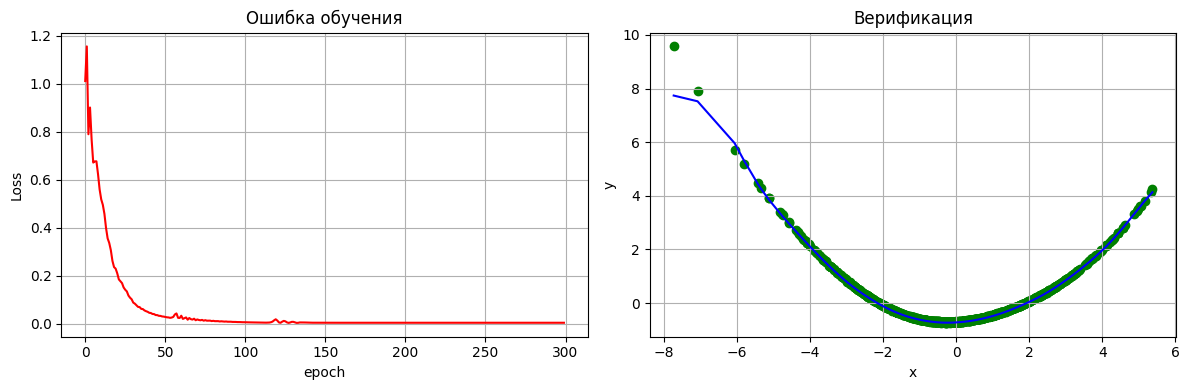

In [158]:
import matplotlib.pyplot as plt
import torch
import torch.nn as nn
import torch.optim as optim
import torch.optim.lr_scheduler as lr_scheduler
import numpy as np

x, y = create_data(1000)
model = create_model()
losses = train_model(model, x, y)
y_pred = model(x)
print(f'final_loss = {losses[-1]}')
plot_results(x.detach().numpy().flatten(), y.detach().numpy().flatten(), y_pred.detach().numpy().flatten(), losses)

In [ ]:
print(y_pred.detach().numpy().shape)